In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/scratches_246.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/patches_258.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/crazing_241.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/patches_267.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/crazing_270.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/pitted_surface_256.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/pitted_surface_265.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/pitted_surface_287.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/crazing_265.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/rolled-in_scale_288.xml
/kaggle/input/neu-surface-defect-database/NEU-DET/validation/annotations/pitted

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torch.optim.lr_scheduler import ExponentialLR

In [3]:
# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Data paths
train_dir = '/kaggle/input/neu-surface-defect-database/NEU-DET/train/images'
val_dir = '/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images'

Using device: cuda


In [4]:
# Data transformations (equivalent to ImageDataGenerator in TF)
transform = transforms.Compose([
    transforms.Resize((200, 200)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load datasets
train_dataset = datasets.ImageFolder(train_dir, transform=transform)
val_dataset = datasets.ImageFolder(val_dir, transform=transform)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

# Number of classes
num_classes = 6

In [5]:
# Load pretrained EfficientNet-B0
base_model = models.efficientnet_b0(weights='IMAGENET1K_V1')

# Freeze the base model parameters
for param in base_model.parameters():
    param.requires_grad = False

# Modify the classifier to match our number of classes
base_model.classifier = nn.Sequential(
    nn.Dropout(0.5),
    nn.Linear(in_features=1280, out_features=256),  # EfficientNet-B0 feature dimension is 1280
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(in_features=256, out_features=num_classes)
)

# Move model to device
model = base_model.to(device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 103MB/s] 


In [6]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
initial_learning_rate = 0.001
optimizer = optim.Adam(model.parameters(), lr=initial_learning_rate)

# Learning rate scheduler - exponential decay similar to the TF code
scheduler = ExponentialLR(optimizer, gamma=0.9) # gamma=0.9 is approximately equivalent to exp(-0.1)

In [7]:
# Training function
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    
    for epoch in range(num_epochs):
        print(f'Epoch {epoch+1}/{num_epochs}')
        print('-' * 10)
        
        # Training phase
        model.train()
        running_loss = 0.0
        running_corrects = 0
        
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            optimizer.zero_grad()
            
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)
            
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)
        
        scheduler.step()
        
        epoch_loss = running_loss / len(train_dataset)
        epoch_acc = running_corrects.double() / len(train_dataset)
        
        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc.item())
        
        print(f'Train Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
        
        # Validation phase
        model.eval()
        running_loss = 0.0
        running_corrects = 0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)
                
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
        
        epoch_loss = running_loss / len(val_dataset)
        epoch_acc = running_corrects.double() / len(val_dataset)
        
        history['val_loss'].append(epoch_loss)
        history['val_acc'].append(epoch_acc.item())
        
        print(f'Val Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
    
    return history

In [8]:
# Print model summary 
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {count_parameters(model)}")

Trainable parameters: 329478


In [9]:
# First training phase (base model frozen)
print("Training with frozen base model")
history_frozen = train_model(model, criterion, optimizer, scheduler, num_epochs=10)

Training with frozen base model
Epoch 1/10
----------
Train Loss: 0.6527 Acc: 0.8056
Val Loss: 0.2392 Acc: 0.9028
Epoch 2/10
----------
Train Loss: 0.2458 Acc: 0.9243
Val Loss: 0.1377 Acc: 0.9556
Epoch 3/10
----------
Train Loss: 0.1814 Acc: 0.9319
Val Loss: 0.1168 Acc: 0.9750
Epoch 4/10
----------
Train Loss: 0.1057 Acc: 0.9618
Val Loss: 0.0730 Acc: 0.9806
Epoch 5/10
----------
Train Loss: 0.1961 Acc: 0.9361
Val Loss: 0.0797 Acc: 0.9722
Epoch 6/10
----------
Train Loss: 0.1633 Acc: 0.9410
Val Loss: 0.1046 Acc: 0.9500
Epoch 7/10
----------
Train Loss: 0.1180 Acc: 0.9535
Val Loss: 0.0801 Acc: 0.9806
Epoch 8/10
----------
Train Loss: 0.1380 Acc: 0.9563
Val Loss: 0.0822 Acc: 0.9639
Epoch 9/10
----------
Train Loss: 0.1216 Acc: 0.9542
Val Loss: 0.1051 Acc: 0.9611
Epoch 10/10
----------
Train Loss: 0.1201 Acc: 0.9556
Val Loss: 0.0892 Acc: 0.9694


In [10]:
# First freeze all layers
for param in base_model.parameters():
    param.requires_grad = False

# Then unfreeze the last few blocks (features.7 and features.8 in EfficientNet-B0)
for name, param in base_model.named_parameters():
    if 'features.7' in name or 'features.8' in name or 'classifier' in name:
        param.requires_grad = True

In [11]:
# Update optimizer with lower learning rate
optimizer_fine_tune = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0001)
scheduler_fine_tune = ExponentialLR(optimizer_fine_tune, gamma=0.9)

In [12]:
# Continue training
history_fine_tune = train_model(model, criterion, optimizer_fine_tune, scheduler_fine_tune, num_epochs=15)

Epoch 1/15
----------
Train Loss: 0.1028 Acc: 0.9597
Val Loss: 0.0393 Acc: 0.9861
Epoch 2/15
----------
Train Loss: 0.0701 Acc: 0.9771
Val Loss: 0.0380 Acc: 0.9861
Epoch 3/15
----------
Train Loss: 0.0679 Acc: 0.9785
Val Loss: 0.0296 Acc: 0.9917
Epoch 4/15
----------
Train Loss: 0.0752 Acc: 0.9750
Val Loss: 0.0191 Acc: 0.9972
Epoch 5/15
----------
Train Loss: 0.0438 Acc: 0.9868
Val Loss: 0.0210 Acc: 0.9944
Epoch 6/15
----------
Train Loss: 0.0536 Acc: 0.9806
Val Loss: 0.0275 Acc: 0.9944
Epoch 7/15
----------
Train Loss: 0.0386 Acc: 0.9889
Val Loss: 0.0221 Acc: 0.9944
Epoch 8/15
----------
Train Loss: 0.0367 Acc: 0.9882
Val Loss: 0.0098 Acc: 0.9972
Epoch 9/15
----------
Train Loss: 0.0386 Acc: 0.9868
Val Loss: 0.0166 Acc: 0.9972
Epoch 10/15
----------
Train Loss: 0.0491 Acc: 0.9840
Val Loss: 0.0138 Acc: 0.9972
Epoch 11/15
----------
Train Loss: 0.0436 Acc: 0.9875
Val Loss: 0.0125 Acc: 0.9972
Epoch 12/15
----------
Train Loss: 0.0318 Acc: 0.9882
Val Loss: 0.0094 Acc: 0.9972
Epoch 13/15
-

In [13]:
history = {
    'train_loss': history_frozen['train_loss'] + history_fine_tune['train_loss'],
    'train_acc': history_frozen['train_acc'] + history_fine_tune['train_acc'],
    'val_loss': history_frozen['val_loss'] + history_fine_tune['val_loss'],
    'val_acc': history_frozen['val_acc'] + history_fine_tune['val_acc']
}

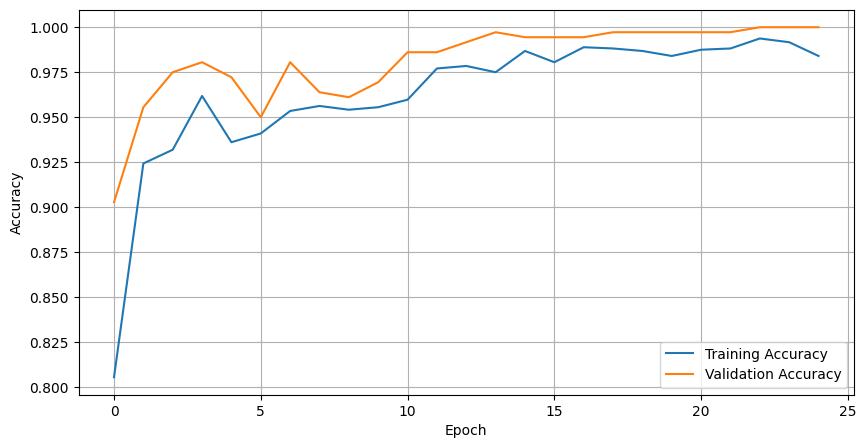

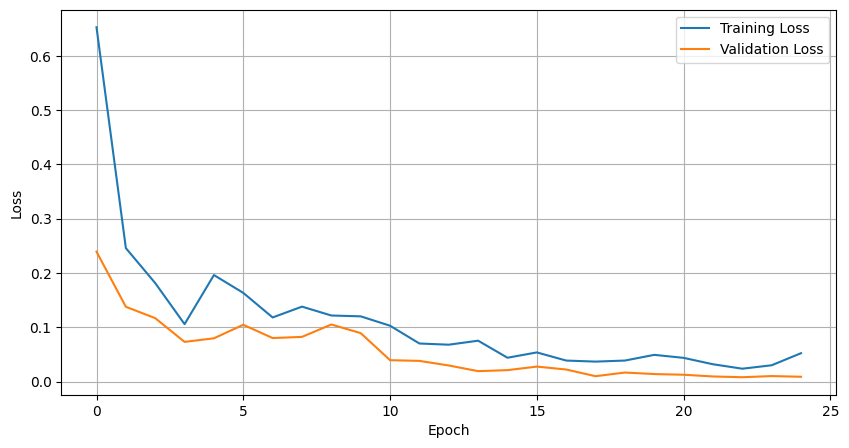

In [14]:
# Plot training and validation accuracy
def plot_history(history):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train_acc'], label='Training Accuracy')
    plt.plot(history['val_acc'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot training and validation loss
def plot_loss_history(history):
    plt.figure(figsize=(10, 5))
    plt.plot(history['train_loss'], label='Training Loss')
    plt.plot(history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

# Plot the training history
plot_history(history)
plot_loss_history(history)

In [15]:
# Save the model
torch.save(model.state_dict(), 'best_model.pth')
print("Model saved as 'best_model.pth'")

Model saved as 'best_model.pth'
